# Use Monte Carlo method to estimate the value of $\pi$

Author: Yao Chengxi

## Introduction

A Monte Carlo method$^1$ is an algorithm that uses random numbers to solve a problem. In this notebook, I'm going to plot a unit square and a quarter circle inscribed within the square, so that $\pi$ can be calculated by area of quarter circle/area of unit square, which is $\pi$/4 .

Then I will generate 1000 random points, and count the number of points that within the quarter circle. The ratio of the number of points within the quarter circle and the total number of points should be approximately $\pi$/4 . As we multiplying it by 4, we get an approximation of $\pi$

## Coding

In [2]:
!pip install numpy matplotlib


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
#define the function that estimate $\pi$
def pi(num):
    '''This function will use generate 'num' random value and use those value to return pi'''
    # This function will use generate 'num' random value and use those value to return pi
    n_inside = 0
    for i in range(num):
        x = np.random.rand()
        y = np.random.rand()
        if (x**2 + y**2) < 1:
            n_inside += 1

    pi_approx = 4 * n_inside / num

    return pi_approx

    # code of estimate pi adapted from Unit5Notes

Create a figure of unit square and a quarter circle inside it

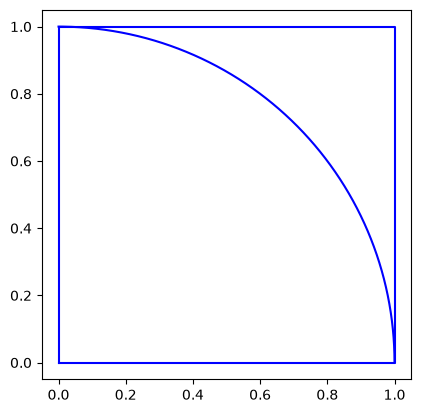

In [5]:
# Create a figure
plt.figure()

def draw_shapes():
    """Draw a unit square and inscribed quarter-circle."""
    # Draw quarter circle with unit radius
    theta_circ = np.linspace(0,np.pi/2,1001)
    x_circ     = np.cos(theta_circ)
    y_circ     = np.sin(theta_circ)
    plt.plot(x_circ,y_circ,'-b')
    plt.gca().set_aspect('equal') # set aspect ratio so shape not distorted

    # Draw unit square
    plt.plot([0,1,1,0,0],[0,0,1,1,0],'b')
    
# Draw unit square and inscribed quarter-circle
draw_shapes()

# ploting code adapted from Unit5Notes

Plot the random points on it

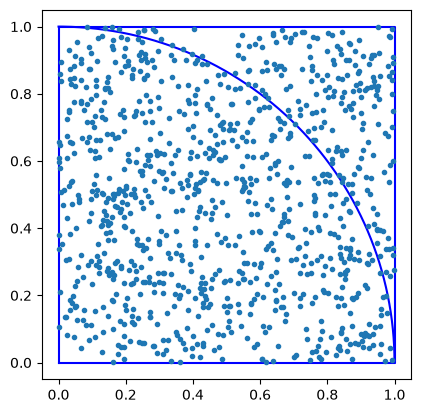

In [6]:
# Create figure with unit square and inscribed quarter-circle
plt.figure()
draw_shapes()

# Generate random arrays of x and y coordinates within unit square
n_points = 1000
x_points = np.random.rand(n_points)
y_points = np.random.rand(n_points)

# Plot generated points
plt.plot(x_points,y_points,'.');

# ploting code adapted from Unit5Notes

So the estimate of $\pi$ in this case is:

In [7]:
print(pi(n_points))

3.092


Repeat it for 10 times, and store the values into an array, then we get:

In [8]:
n_values=10

# Prepare an array to store the results
pi_values = np.empty(n_values)

# Calculate n_values separate estimate of pi, each using n_points random points
for i in range(n_values):
    pi_values[i]=pi(n_points)

print("Estimates of pi:")
print(pi_values)

# code adapted from Unit5Notes

Estimates of pi:
[3.224 3.156 3.144 3.196 3.176 3.132 3.188 3.164 3.12  3.164]


For a histogram we want to repeat the process a larger number of times.

In [9]:
n_values=10000

# Prepare an array to store the results
pi_values = np.empty(n_values)

# Calculate n_values separate estimate of pi, each using n_points random points
for i in range(n_values):
    pi_values[i]=pi(n_points)


In [10]:
N=1000000
x = np.random.rand(N)
y = np.random.rand(N)
dist_sq = x**2 + y**2
inside_circle = dist_sq <= 1.0
num_inside = np.sum(inside_circle)
pi_estimate = 4 * num_inside / N
print(pi_estimate)

3.137368


Now that we have an array of values, we can plot them as a histogram.

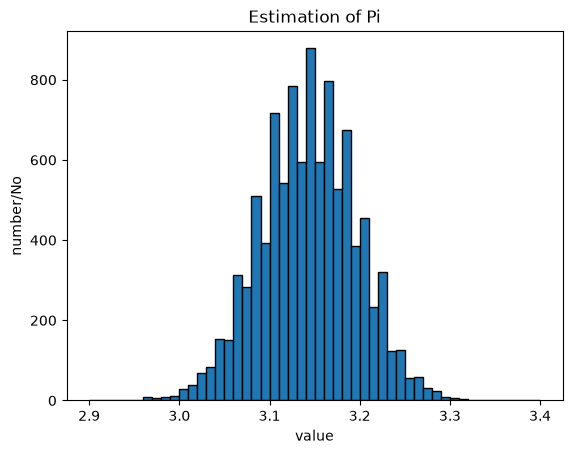

In [11]:
plt.rcParams['patch.force_edgecolor'] = True
plt.figure()
plt.title('Estimation of Pi')
plt.xlabel('value')
plt.ylabel('number/No')
plt.hist(pi_values, bins=50, range=(2.9,3.4));

# ploting code adapted from Unit5Notes

## Conclusion

Overall, the histogram shows a normal distribution trend of estimation of Pi. Most estimations of $\pi$ are between 3.14 and 3.15. In this case, the value of $\pi$ is approximate 3.145

I found that the program use many time when n_value is large. So, to optimise code, I calculate all random data at the same time rather than using for loop, and it really save lots of time (>99%)

## Reference

1: Unit5Notes